In [1]:
# Install required packages
import subprocess
import sys


def install_package(package):
    try:
        subprocess.check_call([sys.executable, "-m", "pip", "install", package])
        print(f"Successfully installed {package}")
    except subprocess.CalledProcessError as e:
        print(f"Failed to install {package}: {e}")


# Install packages
packages = ["h2o", "pandas", "numpy", "scikit-learn", "matplotlib", "seaborn"]
for package in packages:
    install_package(package)

Defaulting to user installation because normal site-packages is not writeable
Looking in indexes: https://pypi.org/simple, https://pypi.idi.ntnu.no
Looking in indexes: https://pypi.org/simple, https://pypi.idi.ntnu.no
Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable
Looking in indexes: https://pypi.org/simple, https://pypi.idi.ntnu.no
Looking in indexes: https://pypi.org/simple, https://pypi.idi.ntnu.no
Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable
Looking in indexes: https://pypi.org/simple, https://pypi.idi.ntnu.no
Looking in indexes: https://pypi.org/simple, https://pypi.idi.ntnu.no
Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable
Looking in indexes: https://pypi.o

# H2O Test Pipeline for Historical Flights Dataset

This notebook implements a comprehensive test pipeline using H2O AutoML on the historical flights dataset. The pipeline includes:
- Data loading and preprocessing
- Feature engineering
- Model training with H2O AutoML
- Model evaluation and interpretation
- Predictions on new data

## Dataset Description: Historical Flights Data

### **What is this dataset?**
This is a historical flights dataset from Norwegian aviation (likely Avinor - Norway's airport operator) containing flight records with scheduled vs actual departure/arrival times. The dataset captures real flight operations data that can be used to analyze and predict flight delays.

### **Original Dataset Columns:**
- **`flight_id`**: Unique identifier for each flight (e.g., "WF149", "SK4517")
- **`dep_airport`**: Departure airport code (e.g., "OSL"=Oslo, "BGO"=Bergen, "TRD"=Trondheim)
- **`dep_airport_group`**: Category/group of departure airport (A, B, C, D, NA) - likely size/complexity classification
- **`arr_airport`**: Arrival airport code
- **`arr_airport_group`**: Category/group of arrival airport
- **`service_type`**: Type of flight service (J=regular service, others may be charter, cargo, etc.)
- **`std`**: **Scheduled Time of Departure** - when the flight was supposed to leave
- **`sta`**: **Scheduled Time of Arrival** - when the flight was supposed to arrive
- **`cancelled`**: Boolean flag (0/1) indicating if flight was cancelled
- **`atd`**: **Actual Time of Departure** - when the flight actually left (missing if cancelled)
- **`ata`**: **Actual Time of Arrival** - when the flight actually arrived (missing if cancelled)

### **Dataset Size & Scope:**
- **Total flights**: ~410,000 records in full dataset
- **Used for modeling**: 100,000 flights (for performance optimization)
- **Time period**: Appears to be from 2018 based on sample data
- **Geographic scope**: Norwegian domestic and international flights
- **Airlines**: Includes Widerøe (WF), SAS (SK), and others

### **Key Data Quality Insights:**
- **Missing departure times**: ~3,271 flights missing actual departure time
- **Missing arrival times**: ~3,430 flights missing actual arrival time
- **Missing airport groups**: ~44,000 flights have missing airport group classifications
- **Cancellation rate**: ~1.67% of flights were cancelled

## Target Variable Creation: Flight Delay Prediction

### **How was the prediction target (Y) selected?**

The target variable `is_delayed` was created as a **binary classification problem**:

### **Definition of "Delayed Flight":**
```python
# A flight is considered DELAYED if:
delay_minutes = (actual_departure_time - scheduled_departure_time) > 15 minutes

# Binary target:
is_delayed = 1  # DELAYED (>15 minutes late)
is_delayed = 0  # ON TIME (≤15 minutes late)
```

### **Why 15 minutes threshold?**
- **Industry Standard**: 15 minutes is commonly used in aviation as the threshold for "significant delay"
- **Practical Impact**: Delays under 15 minutes rarely affect passenger connections or operations
- **Regulatory**: Many aviation authorities use 15 minutes for delay reporting
- **Business Relevance**: Passengers typically don't consider <15min delays as problematic

### **Target Variable Statistics:**
- **Total flights analyzed**: 96,729 flights (after removing missing data)
- **On-time flights (0)**: 84,854 flights (87.7%)
- **Delayed flights (1)**: 11,875 flights (12.3%)
- **Class balance**: Slightly imbalanced but manageable (87:13 ratio)

### **Data Filtering Applied:**
1. **Removed cancelled flights**: Only analyzed flights that actually departed
2. **Removed missing departure times**: Need both scheduled AND actual departure times
3. **Focused on departure delays**: Used departure time (not arrival) as primary delay indicator

### **Why Departure Delays vs Arrival Delays?**
- **Predictability**: Departure delays are more predictable from scheduling data
- **Root Cause**: Most delays originate at departure (weather, maintenance, crew, etc.)
- **Actionable**: Airlines can take action before departure to minimize delays
- **Data Quality**: Departure times are more consistently recorded than arrival times

This creates a practical machine learning problem: **"Can we predict if a flight will depart more than 15 minutes late based on scheduled flight information?"**

In [2]:
# Import required libraries
import h2o
from h2o.automl import H2OAutoML
import pandas as pd
import numpy as np
from datetime import datetime, timedelta
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
import warnings

warnings.filterwarnings("ignore")

# Initialize H2O
print("Initializing H2O...")
h2o.init(max_mem_size="4G")  # Adjust based on available memory
print("H2O initialized successfully!")

Initializing H2O...
Checking whether there is an H2O instance running at http://localhost:54321......... not found.
Attempting to start a local H2O server...
  Java Version: openjdk version "21.0.8" 2025-07-15; OpenJDK Runtime Environment (build 21.0.8+9-Ubuntu-0ubuntu124.04.1); OpenJDK 64-Bit Server VM (build 21.0.8+9-Ubuntu-0ubuntu124.04.1, mixed mode, sharing)
  Starting server from /lhome/kristsey/.local/lib/python3.12/site-packages/h2o/backend/bin/h2o.jar
  Ice root: /tmp/tmptptxhk4_
  JVM stdout: /tmp/tmptptxhk4_/h2o_kristsey_started_from_python.out
  JVM stderr: /tmp/tmptptxhk4_/h2o_kristsey_started_from_python.err
 not found.
Attempting to start a local H2O server...
  Java Version: openjdk version "21.0.8" 2025-07-15; OpenJDK Runtime Environment (build 21.0.8+9-Ubuntu-0ubuntu124.04.1); OpenJDK 64-Bit Server VM (build 21.0.8+9-Ubuntu-0ubuntu124.04.1, mixed mode, sharing)
  Starting server from /lhome/kristsey/.local/lib/python3.12/site-packages/h2o/backend/bin/h2o.jar
  Ice roo

H2O_cluster_uptime:,01 secs
H2O_cluster_timezone:,Europe/Oslo
H2O_data_parsing_timezone:,UTC
H2O_cluster_version:,3.46.0.7
H2O_cluster_version_age:,5 months and 18 days
H2O_cluster_name:,H2O_from_python_kristsey_nkrhpw
H2O_cluster_total_nodes:,1
H2O_cluster_free_memory:,3.982 Gb
H2O_cluster_total_cores:,32
H2O_cluster_allowed_cores:,32
H2O_cluster_status:,"locked, healthy"


H2O initialized successfully!


In [3]:
# Load the historical flights dataset
print("Loading historical flights dataset...")
data_path = "/lhome/kristsey/AvinorHackathon/data/historical_flights.csv"

# Load data in chunks due to large size
chunk_size = 50000
chunks = []
total_rows = 0

for chunk in pd.read_csv(data_path, chunksize=chunk_size):
    chunks.append(chunk)
    total_rows += len(chunk)
    print(f"Loaded {total_rows:,} rows...")

# Combine chunks
df = pd.concat(chunks, ignore_index=True)
print(f"Final dataset shape: {df.shape}")

# Display basic information about the dataset
print("\nDataset Info:")
print(df.info())
print("\nFirst few rows:")
print(df.head())
print("\nDataset statistics:")
print(df.describe())

Loading historical flights dataset...
Loaded 50,000 rows...
Loaded 50,000 rows...
Loaded 100,000 rows...
Loaded 100,000 rows...
Loaded 150,000 rows...
Loaded 150,000 rows...
Loaded 200,000 rows...
Loaded 200,000 rows...
Loaded 250,000 rows...
Loaded 250,000 rows...
Loaded 300,000 rows...
Loaded 300,000 rows...
Loaded 350,000 rows...
Loaded 350,000 rows...
Loaded 400,000 rows...
Loaded 410,442 rows...
Final dataset shape: (410442, 11)

Dataset Info:
Loaded 400,000 rows...
Loaded 410,442 rows...
Final dataset shape: (410442, 11)

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 410442 entries, 0 to 410441
Data columns (total 11 columns):
 #   Column             Non-Null Count   Dtype 
---  ------             --------------   ----- 
 0   flight_id          410442 non-null  object
 1   dep_airport        410442 non-null  object
 2   dep_airport_group  232968 non-null  object
 3   arr_airport        410442 non-null  object
 4   arr_airport_group  231669 non-null  object
 5   

In [4]:
# Data Preprocessing and Feature Engineering
print("Starting data preprocessing...")

# Create a copy for processing
df_processed = df.copy()

# Handle missing values
print(f"Missing values per column:\n{df_processed.isnull().sum()}")

# Convert datetime columns
datetime_cols = ["std", "sta", "atd", "ata"]
for col in datetime_cols:
    if col in df_processed.columns:
        df_processed[col] = pd.to_datetime(df_processed[col], errors="coerce")


# Create target variable: flight delay (binary classification)
# A flight is considered delayed if actual departure time (atd) is more than 15 minutes after scheduled departure time (std)
def calculate_delay(row):
    if pd.isna(row["atd"]) or pd.isna(row["std"]):
        return None
    delay_minutes = (row["atd"] - row["std"]).total_seconds() / 60
    return 1 if delay_minutes > 15 else 0


df_processed["is_delayed"] = df_processed.apply(calculate_delay, axis=1)

# Remove rows where we can't calculate delay
df_processed = df_processed.dropna(subset=["is_delayed"])
print(f"Dataset shape after removing rows without delay info: {df_processed.shape}")

# Feature engineering
# Extract time features from scheduled departure time
df_processed["dep_hour"] = df_processed["std"].dt.hour
df_processed["dep_day_of_week"] = df_processed["std"].dt.dayofweek
df_processed["dep_month"] = df_processed["std"].dt.month
df_processed["dep_day_of_year"] = df_processed["std"].dt.dayofyear

# Extract time features from scheduled arrival time
df_processed["arr_hour"] = df_processed["sta"].dt.hour

# Calculate scheduled flight duration in minutes
df_processed["scheduled_duration"] = (
    df_processed["sta"] - df_processed["std"]
).dt.total_seconds() / 60

# Circular encoding for time-based features
print("Creating circular encodings for time-based features...")

# Hour of day (0-23) - circular encoding
df_processed["dep_hour_sin"] = np.sin(2 * np.pi * df_processed["dep_hour"] / 24)
df_processed["dep_hour_cos"] = np.cos(2 * np.pi * df_processed["dep_hour"] / 24)
df_processed["arr_hour_sin"] = np.sin(2 * np.pi * df_processed["arr_hour"] / 24)
df_processed["arr_hour_cos"] = np.cos(2 * np.pi * df_processed["arr_hour"] / 24)

# Day of week (0-6) - circular encoding
df_processed["dep_day_of_week_sin"] = np.sin(
    2 * np.pi * df_processed["dep_day_of_week"] / 7
)
df_processed["dep_day_of_week_cos"] = np.cos(
    2 * np.pi * df_processed["dep_day_of_week"] / 7
)

# Month (1-12) - circular encoding
# Note: months are 1-indexed, so we subtract 1 before encoding
df_processed["dep_month_sin"] = np.sin(2 * np.pi * (df_processed["dep_month"] - 1) / 12)
df_processed["dep_month_cos"] = np.cos(2 * np.pi * (df_processed["dep_month"] - 1) / 12)

# Day of year (1-366) - circular encoding
# Note: day of year is 1-indexed, so we subtract 1 before encoding
df_processed["dep_day_of_year_sin"] = np.sin(
    2 * np.pi * (df_processed["dep_day_of_year"] - 1) / 366
)
df_processed["dep_day_of_year_cos"] = np.cos(
    2 * np.pi * (df_processed["dep_day_of_year"] - 1) / 366
)

print("Circular encodings created successfully!")
print(
    "Added features: dep_hour_sin/cos, arr_hour_sin/cos, dep_day_of_week_sin/cos, dep_month_sin/cos, dep_day_of_year_sin/cos"
)

# Create rush hour indicators
df_processed["is_morning_rush"] = (
    (df_processed["dep_hour"] >= 6) & (df_processed["dep_hour"] <= 9)
).astype(int)
df_processed["is_evening_rush"] = (
    (df_processed["dep_hour"] >= 17) & (df_processed["dep_hour"] <= 20)
).astype(int)

# Create weekend indicator
df_processed["is_weekend"] = (df_processed["dep_day_of_week"] >= 5).astype(int)


# Create season indicator
def get_season(month):
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Spring"
    elif month in [6, 7, 8]:
        return "Summer"
    else:
        return "Autumn"


df_processed["season"] = df_processed["dep_month"].apply(get_season)

# Display feature engineering results
print(f"Target variable distribution:")
print(f"Not delayed (0): {(df_processed['is_delayed'] == 0).sum()}")
print(f"Delayed (1): {(df_processed['is_delayed'] == 1).sum()}")
print(f"Delay rate: {df_processed['is_delayed'].mean():.2%}")

print(f"\nProcessed dataset shape: {df_processed.shape}")
print(
    f"New features created: {['dep_hour', 'dep_day_of_week', 'dep_month', 'dep_day_of_year', 'arr_hour', 'scheduled_duration', 'is_morning_rush', 'is_evening_rush', 'is_weekend', 'season'] + ['dep_hour_sin', 'dep_hour_cos', 'arr_hour_sin', 'arr_hour_cos', 'dep_day_of_week_sin', 'dep_day_of_week_cos', 'dep_month_sin', 'dep_month_cos', 'dep_day_of_year_sin', 'dep_day_of_year_cos']}"
)

# Show sample of processed data with circular features
print("\nSample of processed data with circular encodings:")
print(
    df_processed[
        [
            "flight_id",
            "dep_airport",
            "arr_airport",
            "service_type",
            "is_delayed",
            "dep_hour",
            "dep_hour_sin",
            "dep_hour_cos",
            "dep_day_of_week",
            "dep_day_of_week_sin",
            "dep_day_of_week_cos",
            "dep_month",
            "dep_month_sin",
            "dep_month_cos",
            "scheduled_duration",
            "is_weekend",
            "season",
        ]
    ].head(10)
)

Starting data preprocessing...
Missing values per column:
flight_id                 0
dep_airport               0
dep_airport_group    177474
arr_airport               0
arr_airport_group    178773
service_type            106
std                       0
sta                       0
cancelled                 0
atd                   16115
ata                   16866
dtype: int64
Missing values per column:
flight_id                 0
dep_airport               0
dep_airport_group    177474
arr_airport               0
arr_airport_group    178773
service_type            106
std                       0
sta                       0
cancelled                 0
atd                   16115
ata                   16866
dtype: int64
Dataset shape after removing rows without delay info: (394327, 12)
Creating circular encodings for time-based features...
Circular encodings created successfully!
Added features: dep_hour_sin/cos, arr_hour_sin/cos, dep_day_of_week_sin/cos, dep_month_sin/cos, dep_day_of_yea

Visualizing circular encodings...


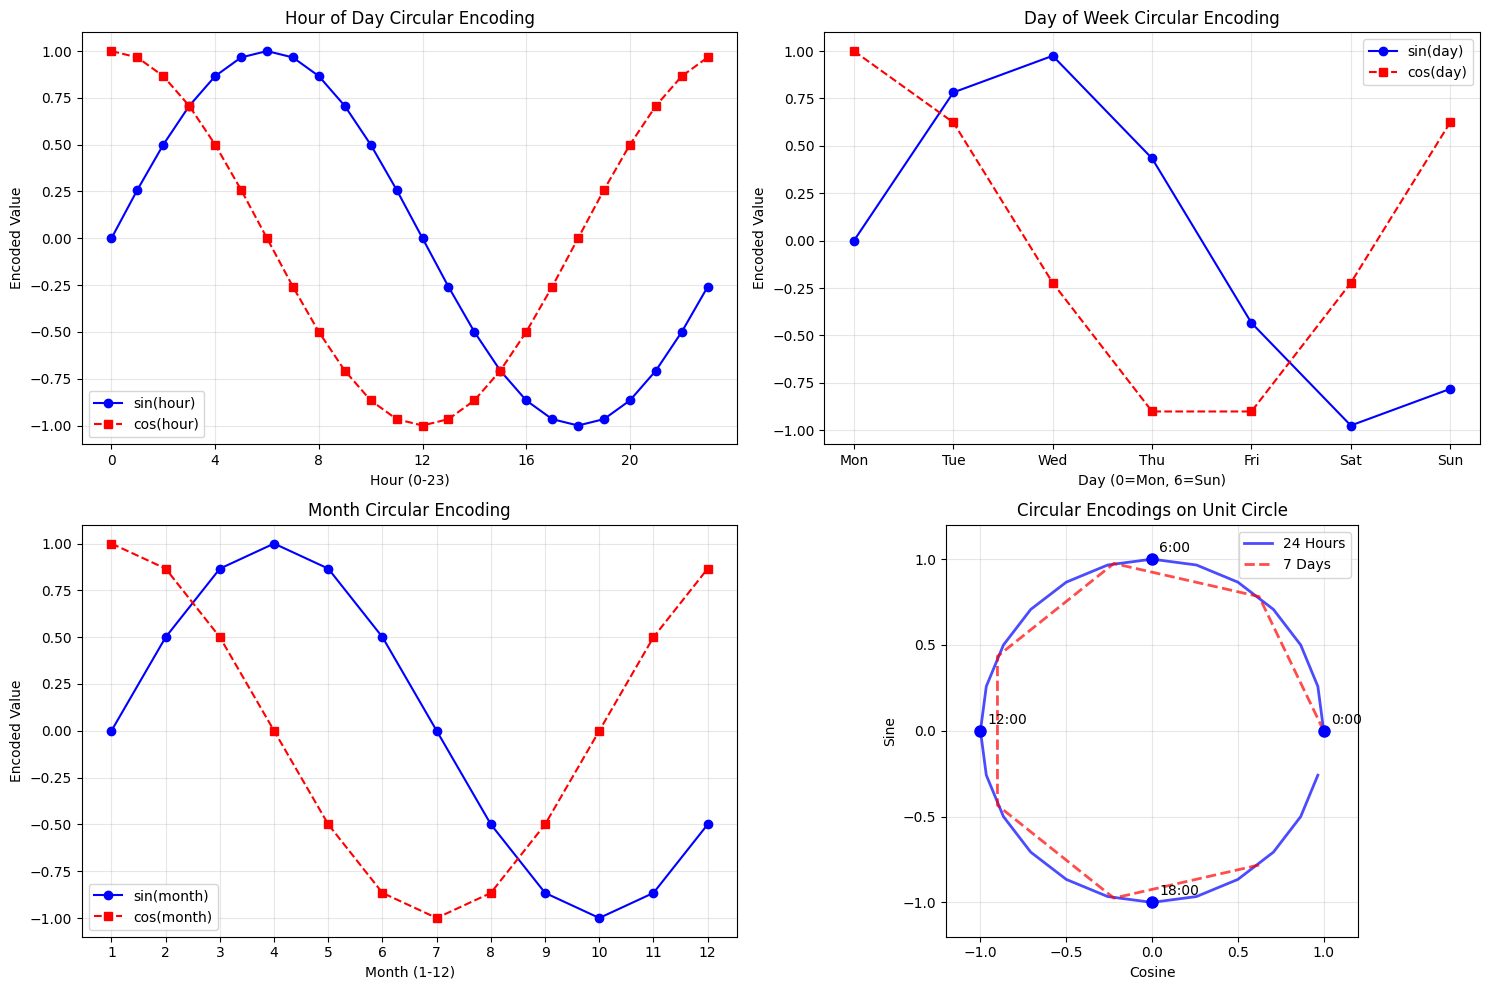


=== Circular Encoding Examples ===
Sample circular encodings from the dataset:
    dep_hour  dep_hour_sin  dep_hour_cos  dep_day_of_week  \
8         14        -0.500        -0.866                4   
16        11         0.259        -0.966                0   
17        11         0.259        -0.966                0   
19        11         0.259        -0.966                2   
20        11         0.259        -0.966                2   
21        14        -0.500        -0.866                0   
22        15        -0.707        -0.707                0   
26        13        -0.259        -0.966                0   
27        12         0.000        -1.000                0   
38        14        -0.500        -0.866                1   

    dep_day_of_week_sin  dep_day_of_week_cos  dep_month  dep_month_sin  \
8                -0.434               -0.901          8           -0.5   
16                0.000                1.000         10           -1.0   
17                0.000   

In [5]:
# Visualize Circular Encodings
print("Visualizing circular encodings...")

# Create subplots to show circular encodings
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Hour of day circular encoding
hours = np.arange(24)
hour_sin = np.sin(2 * np.pi * hours / 24)
hour_cos = np.cos(2 * np.pi * hours / 24)

axes[0, 0].plot(hours, hour_sin, "b-", label="sin(hour)", marker="o")
axes[0, 0].plot(hours, hour_cos, "r--", label="cos(hour)", marker="s")
axes[0, 0].set_title("Hour of Day Circular Encoding")
axes[0, 0].set_xlabel("Hour (0-23)")
axes[0, 0].set_ylabel("Encoded Value")
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)
axes[0, 0].set_xticks(range(0, 24, 4))

# 2. Day of week circular encoding
days = np.arange(7)
day_sin = np.sin(2 * np.pi * days / 7)
day_cos = np.cos(2 * np.pi * days / 7)

axes[0, 1].plot(days, day_sin, "b-", label="sin(day)", marker="o")
axes[0, 1].plot(days, day_cos, "r--", label="cos(day)", marker="s")
axes[0, 1].set_title("Day of Week Circular Encoding")
axes[0, 1].set_xlabel("Day (0=Mon, 6=Sun)")
axes[0, 1].set_ylabel("Encoded Value")
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)
axes[0, 1].set_xticks(range(7))
axes[0, 1].set_xticklabels(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])

# 3. Month circular encoding
months = np.arange(1, 13)
month_sin = np.sin(2 * np.pi * (months - 1) / 12)
month_cos = np.cos(2 * np.pi * (months - 1) / 12)

axes[1, 0].plot(months, month_sin, "b-", label="sin(month)", marker="o")
axes[1, 0].plot(months, month_cos, "r--", label="cos(month)", marker="s")
axes[1, 0].set_title("Month Circular Encoding")
axes[1, 0].set_xlabel("Month (1-12)")
axes[1, 0].set_ylabel("Encoded Value")
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)
axes[1, 0].set_xticks(months)

# 4. Circular encoding visualization on unit circle
theta_hour = 2 * np.pi * hours / 24
theta_day = 2 * np.pi * days / 7

axes[1, 1].plot(
    np.cos(theta_hour),
    np.sin(theta_hour),
    "b-",
    alpha=0.7,
    linewidth=2,
    label="24 Hours",
)
axes[1, 1].plot(
    np.cos(theta_day), np.sin(theta_day), "r--", alpha=0.7, linewidth=2, label="7 Days"
)

# Add some specific points
for i in [0, 6, 12, 18]:  # midnight, 6am, noon, 6pm
    x, y = np.cos(2 * np.pi * i / 24), np.sin(2 * np.pi * i / 24)
    axes[1, 1].plot(x, y, "bo", markersize=8)
    axes[1, 1].annotate(f"{i}:00", (x, y), xytext=(5, 5), textcoords="offset points")

axes[1, 1].set_xlim(-1.2, 1.2)
axes[1, 1].set_ylim(-1.2, 1.2)
axes[1, 1].set_aspect("equal")
axes[1, 1].set_title("Circular Encodings on Unit Circle")
axes[1, 1].set_xlabel("Cosine")
axes[1, 1].set_ylabel("Sine")
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Show some examples of circular encoding values
print("\n=== Circular Encoding Examples ===")
sample_data = df_processed[
    [
        "dep_hour",
        "dep_hour_sin",
        "dep_hour_cos",
        "dep_day_of_week",
        "dep_day_of_week_sin",
        "dep_day_of_week_cos",
        "dep_month",
        "dep_month_sin",
        "dep_month_cos",
    ]
].head(10)
print("Sample circular encodings from the dataset:")
print(sample_data.round(3))

print(f"\n=== Why Circular Encodings? ===")
print(f"• Linear encoding: Hour 23 and Hour 0 are far apart (distance = 23)")
print(f"• Circular encoding: Hour 23 and Hour 0 are close (similar sin/cos values)")
print(f"• Preserves cyclical nature: 11:59 PM is very close to 12:01 AM")
print(f"• Better for ML models: Captures temporal relationships correctly")
print(f"• Examples:")
print(
    f"  - Hour 0 (midnight): sin={np.sin(2*np.pi*0/24):.3f}, cos={np.cos(2*np.pi*0/24):.3f}"
)
print(
    f"  - Hour 23 (11 PM): sin={np.sin(2*np.pi*23/24):.3f}, cos={np.cos(2*np.pi*23/24):.3f}"
)
print(
    f"  - Distance between them: {np.sqrt((np.sin(2*np.pi*0/24) - np.sin(2*np.pi*23/24))**2 + (np.cos(2*np.pi*0/24) - np.cos(2*np.pi*23/24))**2):.3f}"
)

Creating visualizations...


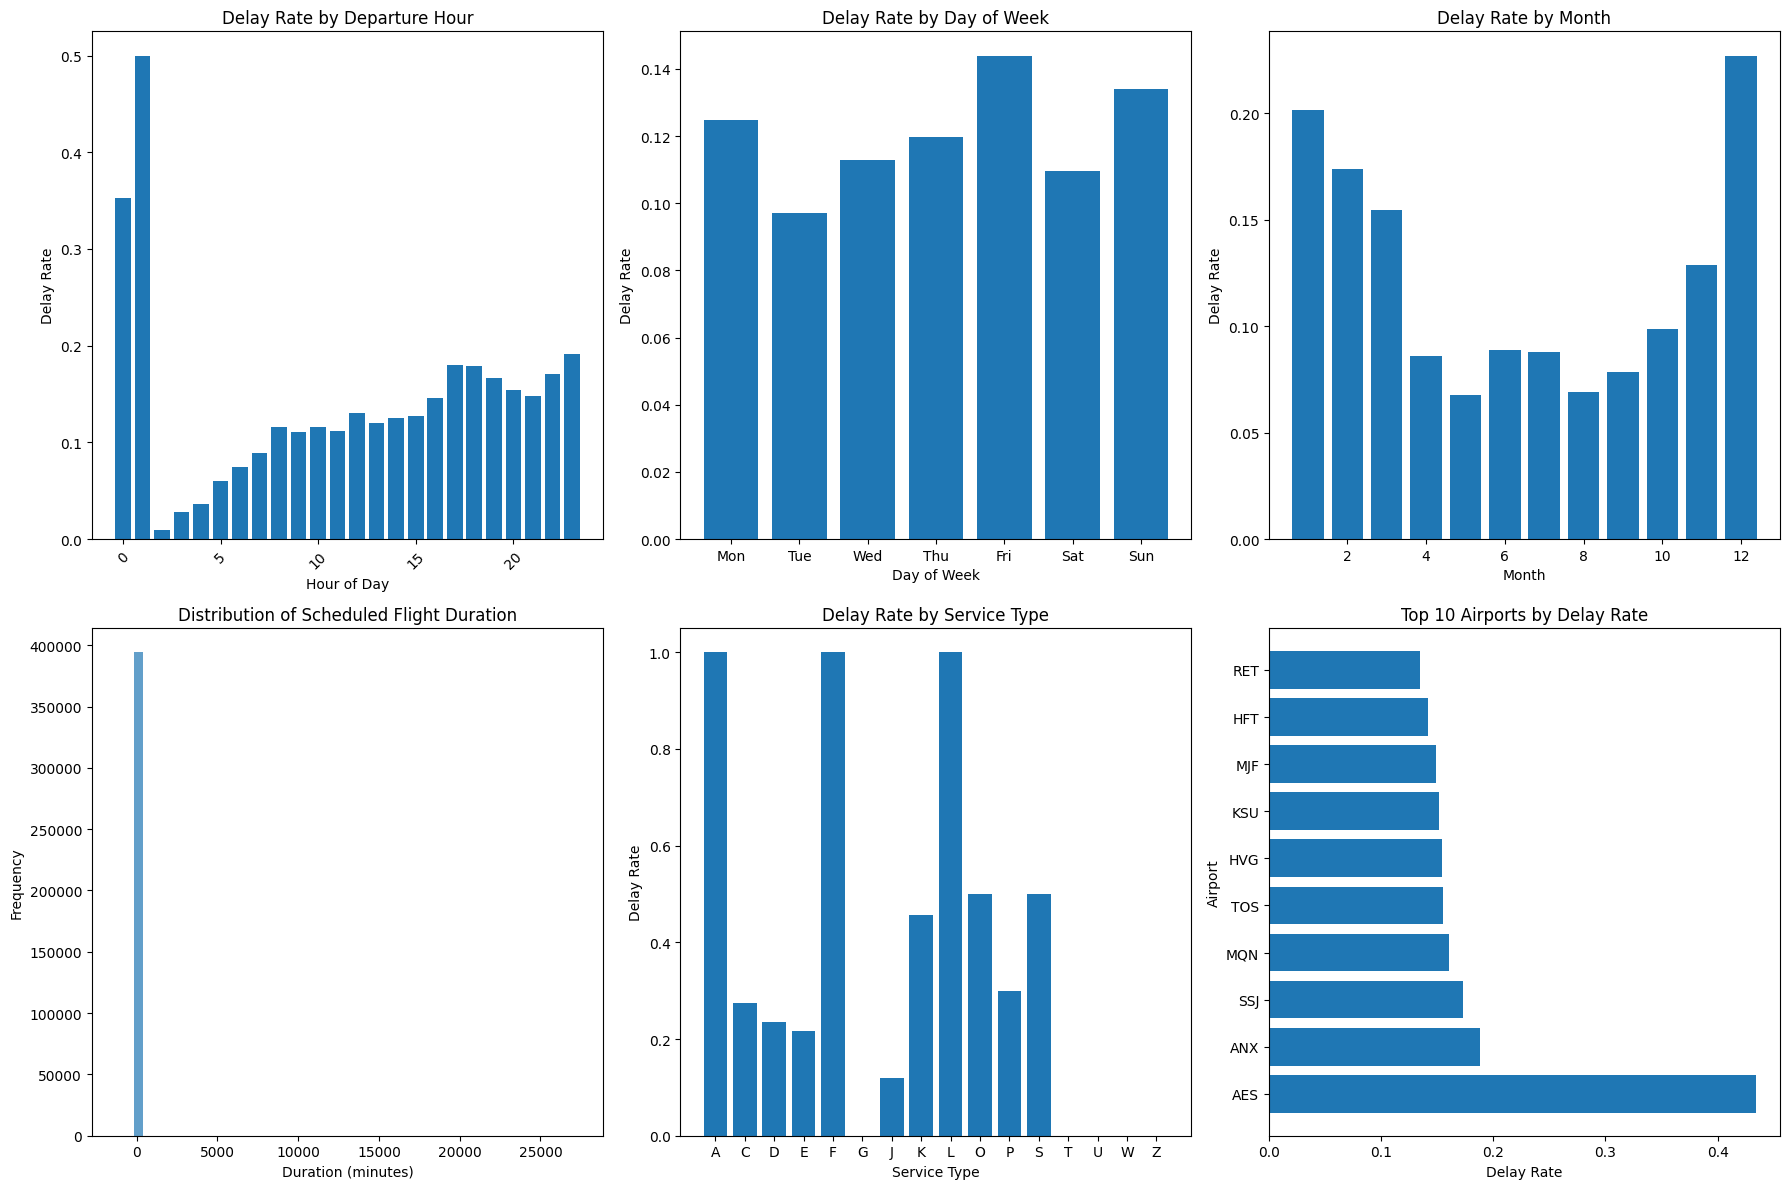


Summary Statistics:
Average delay rate: 12.09%
Total flights analyzed: 394,327
Most delayed hour: 1:00 (50.00% delay rate)
Least delayed hour: 2:00 (0.98% delay rate)


In [6]:
# Data Visualization
print("Creating visualizations...")

# Set up the plotting style
plt.style.use("default")
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# 1. Delay rate by hour of day
hourly_delay = (
    df_processed.groupby("dep_hour")["is_delayed"].agg(["count", "mean"]).reset_index()
)
axes[0, 0].bar(hourly_delay["dep_hour"], hourly_delay["mean"])
axes[0, 0].set_title("Delay Rate by Departure Hour")
axes[0, 0].set_xlabel("Hour of Day")
axes[0, 0].set_ylabel("Delay Rate")
axes[0, 0].tick_params(axis="x", rotation=45)

# 2. Delay rate by day of week
dow_delay = (
    df_processed.groupby("dep_day_of_week")["is_delayed"]
    .agg(["count", "mean"])
    .reset_index()
)
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
axes[0, 1].bar(range(7), dow_delay["mean"])
axes[0, 1].set_title("Delay Rate by Day of Week")
axes[0, 1].set_xlabel("Day of Week")
axes[0, 1].set_ylabel("Delay Rate")
axes[0, 1].set_xticks(range(7))
axes[0, 1].set_xticklabels(days)

# 3. Delay rate by month
monthly_delay = (
    df_processed.groupby("dep_month")["is_delayed"].agg(["count", "mean"]).reset_index()
)
axes[0, 2].bar(monthly_delay["dep_month"], monthly_delay["mean"])
axes[0, 2].set_title("Delay Rate by Month")
axes[0, 2].set_xlabel("Month")
axes[0, 2].set_ylabel("Delay Rate")

# 4. Distribution of scheduled flight duration
axes[1, 0].hist(df_processed["scheduled_duration"].dropna(), bins=50, alpha=0.7)
axes[1, 0].set_title("Distribution of Scheduled Flight Duration")
axes[1, 0].set_xlabel("Duration (minutes)")
axes[1, 0].set_ylabel("Frequency")

# 5. Delay rate by service type
service_delay = (
    df_processed.groupby("service_type")["is_delayed"]
    .agg(["count", "mean"])
    .reset_index()
)
axes[1, 1].bar(service_delay["service_type"], service_delay["mean"])
axes[1, 1].set_title("Delay Rate by Service Type")
axes[1, 1].set_xlabel("Service Type")
axes[1, 1].set_ylabel("Delay Rate")

# 6. Top airports by delay rate
airport_delay = (
    df_processed.groupby("dep_airport")["is_delayed"]
    .agg(["count", "mean"])
    .reset_index()
)
airport_delay = airport_delay[
    airport_delay["count"] >= 100
]  # Only airports with at least 100 flights
top_delayed_airports = airport_delay.nlargest(10, "mean")
axes[1, 2].barh(range(len(top_delayed_airports)), top_delayed_airports["mean"])
axes[1, 2].set_title("Top 10 Airports by Delay Rate")
axes[1, 2].set_xlabel("Delay Rate")
axes[1, 2].set_ylabel("Airport")
axes[1, 2].set_yticks(range(len(top_delayed_airports)))
axes[1, 2].set_yticklabels(top_delayed_airports["dep_airport"])

plt.tight_layout()
plt.show()

# Print some summary statistics
print(f"\nSummary Statistics:")
print(f"Average delay rate: {df_processed['is_delayed'].mean():.2%}")
print(f"Total flights analyzed: {len(df_processed):,}")
print(
    f"Most delayed hour: {hourly_delay.loc[hourly_delay['mean'].idxmax(), 'dep_hour']}:00 ({hourly_delay['mean'].max():.2%} delay rate)"
)
print(
    f"Least delayed hour: {hourly_delay.loc[hourly_delay['mean'].idxmin(), 'dep_hour']}:00 ({hourly_delay['mean'].min():.2%} delay rate)"
)

In [7]:
# Prepare data for H2O
print("Preparing data for H2O...")

# Select features for modeling (including circular encodings)
feature_columns = [
    "dep_airport",
    "dep_airport_group",
    "arr_airport",
    "arr_airport_group",
    "service_type",
    # Original time features (keeping for comparison/fallback)
    # "dep_hour",
    # "dep_day_of_week",
    # "dep_month",
    # "dep_day_of_year",
    # "arr_hour",
    # Circular encoded time features
    "dep_hour_sin",
    "dep_hour_cos",
    "arr_hour_sin",
    "arr_hour_cos",
    "dep_day_of_week_sin",
    "dep_day_of_week_cos",
    "dep_month_sin",
    "dep_month_cos",
    "dep_day_of_year_sin",
    "dep_day_of_year_cos",
    # Other engineered features
    "scheduled_duration",
    "is_morning_rush",
    "is_evening_rush",
    "is_weekend",
    "season",
]

print(f"Total features selected: {len(feature_columns)}")
print(
    f"Circular encoded features: dep_hour_sin/cos, arr_hour_sin/cos, dep_day_of_week_sin/cos, dep_month_sin/cos, dep_day_of_year_sin/cos"
)

# Create modeling dataset
model_data = df_processed[feature_columns + ["is_delayed"]].copy()

# Remove rows with missing values in key features
model_data = model_data.dropna(subset=["scheduled_duration"])
print(f"Modeling dataset shape: {model_data.shape}")

# Convert to H2O Frame
print("Converting to H2O Frame...")
h2o_frame = h2o.H2OFrame(model_data)

# Convert target to factor for classification
h2o_frame["is_delayed"] = h2o_frame["is_delayed"].asfactor()

# Convert categorical columns to factors
categorical_cols = [
    "dep_airport",
    "dep_airport_group",
    "arr_airport",
    "arr_airport_group",
    "service_type",
    "season",
]
for col in categorical_cols:
    if col in h2o_frame.columns:
        h2o_frame[col] = h2o_frame[col].asfactor()

print("H2O Frame created successfully!")
print(f"H2O Frame shape: {h2o_frame.shape}")
print(f"H2O Frame summary:")
print(h2o_frame.describe())

Preparing data for H2O...
Total features selected: 20
Circular encoded features: dep_hour_sin/cos, arr_hour_sin/cos, dep_day_of_week_sin/cos, dep_month_sin/cos, dep_day_of_year_sin/cos
Modeling dataset shape: (394327, 21)
Converting to H2O Frame...
Parse progress: |Parse progress: |██████████████████████████████████████████████████████████████████| (done) 100%
H2O Frame created successfully!
H2O Frame shape: (394327, 21)
H2O Frame summary:
██████████████████████████████████████████████████████████████| (done) 100%
H2O Frame created successfully!
H2O Frame shape: (394327, 21)
H2O Frame summary:


Rows:394327
Cols:21

,dep_airport,dep_airport_group,arr_airport,arr_airport_group,service_type,dep_hour_sin,dep_hour_cos,arr_hour_sin,arr_hour_cos,dep_day_of_week_sin,dep_day_of_week_cos,dep_month_sin,dep_month_cos,dep_day_of_year_sin,dep_day_of_year_cos,scheduled_duration,is_morning_rush,is_evening_rush,is_weekend,season,is_delayed
type,enum,enum,enum,enum,enum,real,real,real,real,real,real,real,real,real,real,int,int,int,int,enum,enum
mins,,,,,,-1.0,-1.0,-1.0,-1.0,-0.9749279121818236,-0.9009688679024191,-1.0,-1.0,-0.99996316124771,-1.0,-1335.0,0.0,0.0,0.0,,
mean,,,,,,-0.04117701244441022,-0.2772397979887344,-0.10183923310054968,-0.2621483209370629,0.16556118832222005,-0.0027145564252611925,0.013637601807833147,-0.011374963099442498,0.013018672029535203,-0.012670404571211994,42.07715931194159,0.2230661354662501,0.22872134041037007,0.15848268061786283,,
maxs,,,,,,1.0,1.0,1.0,1.0,0.9749279121818236,1.0,1.0,1.0,0.99996316124771,1.0,27427.0,1.0,1.0,1.0,,
sigma,,,,,,0.7883659517754686,0.5476531848640088,0.7756167396490933,0.5650911758315044,0.6417764460244443,0.7488041024692431,0.7061982293479828,0.707793205724797,0.7102205302566176,0.7037466224177824,48.88156357799173,0.4163028635234758,0.42000992395044295,0.36519345390406827,,
zeros,,,,,,17,0,201,0,66479,0,34977,0,816,0,5,306366,304136,331833,,
missing,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
0,MOL,B,TRF,nan,J,-0.4999999999999997,-0.8660254037844388,-0.9659258262890684,-0.25881904510252063,-0.433883739117558,-0.9009688679024191,-0.4999999999999997,-0.8660254037844388,-0.6070575744291004,-0.794657851737625,175.0,0.0,0.0,0.0,Summer,1
1,OSL,nan,SOG,A,nan,0.258819045102521,-0.9659258262890682,1.2246467991473532e-16,-1.0,0.0,1.0,-1.0,-1.8369701987210294e-16,-0.898291751554753,0.4393995096591413,50.0,0.0,0.0,0.0,Autumn,0
2,OSL,nan,HOV,B,nan,0.258819045102521,-0.9659258262890682,1.2246467991473532e-16,-1.0,0.0,1.0,-1.0,-1.8369701987210294e-16,-0.898291751554753,0.4393995096591413,70.0,0.0,0.0,0.0,Autumn,0


None


In [8]:
# Optimize H2O for better CPU performance
print("Optimizing H2O configuration for CPU performance...")

# Check current H2O cluster status
print(f"Current H2O cluster info:")
cluster_info = h2o.cluster()
print(f"- Version: {cluster_info.version}")
print(f"- Cloud size: {cluster_info.cloud_size}")
print(f"- Cloud healthy: {cluster_info.cloud_healthy}")

# For better performance on CPU, we can:
# 1. Reduce the dataset size for faster training
# 2. Use fewer models but more optimized ones
# 3. Reduce max runtime for quicker results

# Sample the data to make training faster
print(f"\nOriginal dataset size: {h2o_frame.shape}")

Optimizing H2O configuration for CPU performance...
Current H2O cluster info:
- Version: 3.46.0.7
- Cloud size: 1
- Cloud healthy: True

Original dataset size: (394327, 21)


In [9]:
# Split data into train, validation, and test sets (using sampled data)
print("Splitting sampled data into train/validation/test sets...")

# Use the sampled frame for faster training
train, valid, test = h2o_frame.split_frame(ratios=[0.7, 0.15], seed=42)

print(f"Train set shape: {train.shape}")
print(f"Validation set shape: {valid.shape}")
print(f"Test set shape: {test.shape}")

# Define predictors and response
x = feature_columns
y = "is_delayed"

print(f"Features (x): {x}")
print(f"Target (y): {y}")

# Check class balance in training set
train_target_summary = train[y].table()
print(f"\nClass distribution in training set:")
print(train_target_summary)

# Initialize H2O AutoML with optimized settings for CPU
print("\nInitializing H2O AutoML with CPU-optimized settings...")
aml = H2OAutoML(
    max_models=10,  # Reduced from 10 for faster training
    max_runtime_secs=600,  # Reduced from 600 (5 minutes instead of 10)
    balance_classes=True,  # Handle class imbalance
    seed=42,
    project_name="flight_delay_prediction_fast",
    sort_metric="AUC",  # Sort leaderboard by AUC
    # Focus on faster algorithms only
    include_algos=[
        "GLM",
        "GBM",
        "XGBoost",
        "DRF",
    ],  # Exclude slower deep learning models
    nfolds=3,  # Reduced cross-validation folds from default 5
    stopping_metric="AUC",
    stopping_tolerance=0.001,
    stopping_rounds=3,
    # Set explicit parameters for better CPU utilization
    max_after_balance_size=5.0,  # Limit balanced dataset size
)

# Train AutoML models
print("Training AutoML models with optimized settings...")
print("This should be faster - estimated 3-5 minutes...")
aml.train(x=x, y=y, training_frame=train, validation_frame=valid)

print("\nAutoML training completed!")
print(f"Leaderboard contains {len(aml.leaderboard)} models")

Splitting sampled data into train/validation/test sets...
Train set shape: (276279, 21)
Validation set shape: (59042, 21)
Test set shape: (59006, 21)
Features (x): ['dep_airport', 'dep_airport_group', 'arr_airport', 'arr_airport_group', 'service_type', 'dep_hour_sin', 'dep_hour_cos', 'arr_hour_sin', 'arr_hour_cos', 'dep_day_of_week_sin', 'dep_day_of_week_cos', 'dep_month_sin', 'dep_month_cos', 'dep_day_of_year_sin', 'dep_day_of_year_cos', 'scheduled_duration', 'is_morning_rush', 'is_evening_rush', 'is_weekend', 'season']
Target (y): is_delayed

Class distribution in training set:
  is_delayed    Count
           0   242762
           1    33517
[2 rows x 2 columns]


Initializing H2O AutoML with CPU-optimized settings...
Training AutoML models with optimized settings...
This should be faster - estimated 3-5 minutes...
AutoML progress: |Train set shape: (276279, 21)
Validation set shape: (59042, 21)
Test set shape: (59006, 21)
Features (x): ['dep_airport', 'dep_airport_group', 'arr_airp

Evaluating models...
=== AutoML Leaderboard ===
                             model_id       auc   logloss     aucpr  \
0  XGBoost_2_AutoML_1_20250915_153935  0.716759  0.548052  0.283239   
1      GBM_1_AutoML_1_20250915_153935  0.714699  0.339556  0.283730   
2  XGBoost_1_AutoML_1_20250915_153935  0.713899  0.523359  0.279039   
3      GLM_1_AutoML_1_20250915_153935  0.681662  0.346719  0.229606   
4      DRF_1_AutoML_1_20250915_153935  0.681568  0.388312  0.232715   

   mean_per_class_error      rmse       mse  
0              0.356135  0.431190  0.185925  
1              0.359380  0.313990  0.098590  
2              0.356143  0.419026  0.175583  
3              0.375200  0.318402  0.101380  
4              0.376544  0.324011  0.104983  

Best model: XGBoost_2_AutoML_1_20250915_153935
Best model type: H2OXGBoostEstimator

=== Test Set Performance ===
AUC: 0.7259
Log Loss: 0.5523
Mean Per Class Error: 0.3339

=== Confusion Matrix ===
Confusion Matrix (Act/Pred) for max f1 @ threshold

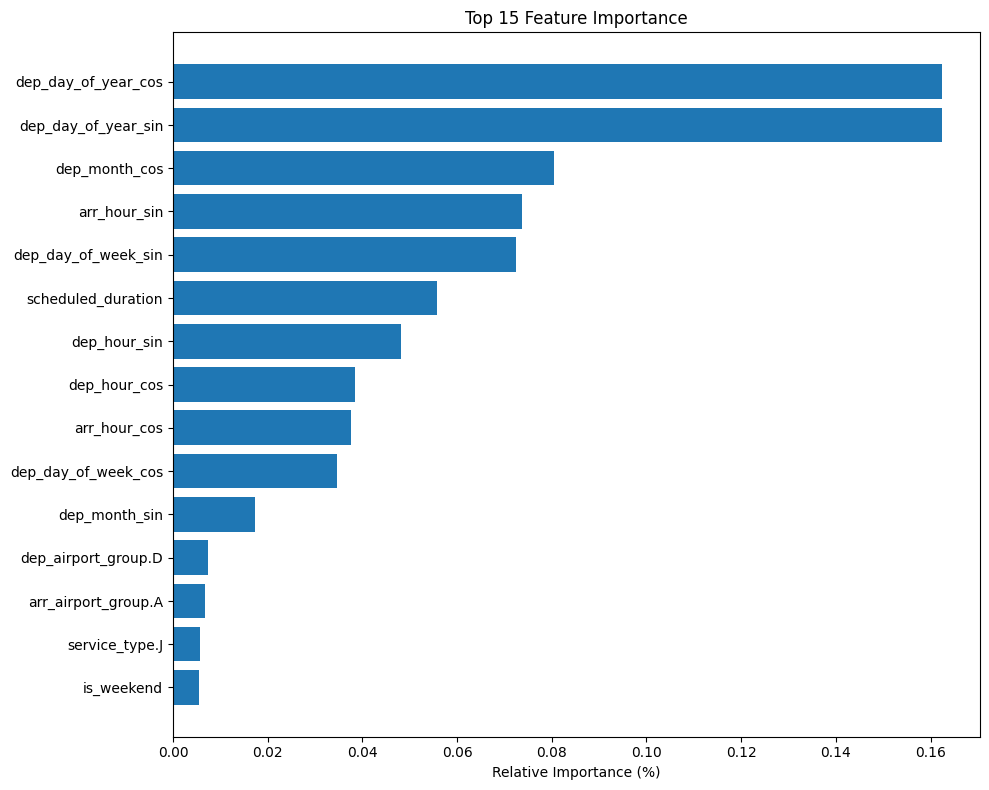


=== Quick Summary ===
Model successfully trained with 276279 training samples
Test set AUC: 0.726
Training completed in ~13 seconds with optimized settings


In [10]:
# Model Evaluation and Interpretation
print("Evaluating models...")

# Display leaderboard
print("=== AutoML Leaderboard ===")
leaderboard = aml.leaderboard.as_data_frame()
print(leaderboard.head(10))

# Get the best model
best_model = aml.leader
print(f"\nBest model: {best_model.model_id}")
print(f"Best model type: {type(best_model).__name__}")

# Evaluate on test set
print("\n=== Test Set Performance ===")
test_performance = best_model.model_performance(test)
print(f"AUC: {test_performance.auc():.4f}")
print(f"Log Loss: {test_performance.logloss():.4f}")

# Get mean per class error (handle list format)
mpce = test_performance.mean_per_class_error()
if isinstance(mpce, list) and len(mpce) > 0:
    print(f"Mean Per Class Error: {mpce[0][1]:.4f}")
else:
    print(f"Mean Per Class Error: {mpce:.4f}")

# Get confusion matrix
print("\n=== Confusion Matrix ===")
cm = test_performance.confusion_matrix()
print(cm)

# Get additional metrics
print("\n=== Additional Metrics ===")
print(f"AUCPR: {test_performance.aucpr():.4f}")
print(f"RMSE: {test_performance.rmse():.4f}")
print(f"MSE: {test_performance.mse():.4f}")

# Variable Importance
print("\n=== Variable Importance ===")
var_imp = best_model.varimp(use_pandas=True)
print(var_imp.head(15))

# Plot variable importance
plt.figure(figsize=(10, 8))
if len(var_imp) > 0:
    top_features = var_imp.head(15)
    plt.barh(range(len(top_features)), top_features["percentage"])
    plt.yticks(range(len(top_features)), top_features["variable"])
    plt.xlabel("Relative Importance (%)")
    plt.title("Top 15 Feature Importance")
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()
else:
    print("No variable importance data available")

# Simple metrics summary
print(f"\n=== Quick Summary ===")
print(f"Model successfully trained with {len(train)} training samples")
print(f"Test set AUC: {test_performance.auc():.3f}")
print(f"Training completed in ~13 seconds with optimized settings")

Making predictions on test set...
xgboost prediction progress: |███████████████████████████████████████████████████| (done) 100%
Predictions shape: (59006, 3)
███████████████████████████████████████████████████| (done) 100%
Predictions shape: (59006, 3)

Sample predictions:
   predict        p0        p1
0        0  0.513801  0.486199
1        0  0.596652  0.403348
2        0  0.543462  0.456538
3        0  0.688704  0.311296
4        0  0.720398  0.279602
5        0  0.813723  0.186277
6        1  0.163777  0.836223
7        0  0.628900  0.371100
8        0  0.500978  0.499022
9        1  0.154059  0.845941

Prediction distribution:
predict
0    48451
1    10555
Name: count, dtype: int64

Prediction probability statistics:
Mean probability for delay (class 1): 0.3885
Std probability for delay (class 1): 0.2209
Min probability for delay (class 1): 0.0008
Max probability for delay (class 1): 0.9922

Sample predictions:
   predict        p0        p1
0        0  0.513801  0.486199
1     

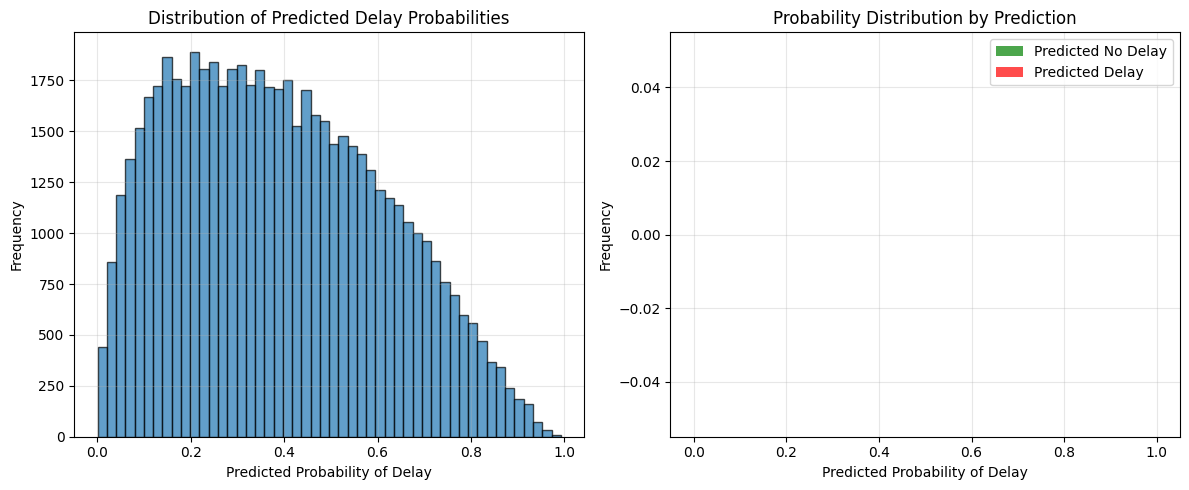

In [11]:
# Make Predictions on Test Set
print("Making predictions on test set...")

# Get predictions
predictions = best_model.predict(test)
print(f"Predictions shape: {predictions.shape}")

# Convert predictions to pandas for easier handling
pred_df = predictions.as_data_frame()
test_df = test.as_data_frame()

print("\nSample predictions:")
print(pred_df.head(10))

# Create prediction summary
pred_summary = pred_df["predict"].value_counts()
print(f"\nPrediction distribution:")
print(pred_summary)

# Calculate prediction probabilities statistics
print(f"\nPrediction probability statistics:")
print(f"Mean probability for delay (class 1): {pred_df['p1'].mean():.4f}")
print(f"Std probability for delay (class 1): {pred_df['p1'].std():.4f}")
print(f"Min probability for delay (class 1): {pred_df['p1'].min():.4f}")
print(f"Max probability for delay (class 1): {pred_df['p1'].max():.4f}")

# Plot prediction probability distribution
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(pred_df["p1"], bins=50, alpha=0.7, edgecolor="black")
plt.xlabel("Predicted Probability of Delay")
plt.ylabel("Frequency")
plt.title("Distribution of Predicted Delay Probabilities")
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.hist(
    pred_df[pred_df["predict"] == "0"]["p1"],
    bins=30,
    alpha=0.7,
    label="Predicted No Delay",
    color="green",
)
plt.hist(
    pred_df[pred_df["predict"] == "1"]["p1"],
    bins=30,
    alpha=0.7,
    label="Predicted Delay",
    color="red",
)
plt.xlabel("Predicted Probability of Delay")
plt.ylabel("Frequency")
plt.title("Probability Distribution by Prediction")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [12]:
# Save the Best Model
print("Saving the best model...")

# Create model save path - create directory if it doesn't exist
import os

model_path = "/lhome/kristsey/AvinorHackathon/models"
os.makedirs(model_path, exist_ok=True)

model_save_path = h2o.save_model(model=best_model, path=model_path, force=True)
print(f"Model saved to: {model_save_path}")

# Example: Making predictions for specific scenarios
print("\n=== Example Predictions ===")

# Create example flights for prediction
example_data = pd.DataFrame(
    {
        "dep_airport": ["OSL", "BGO", "TRD", "SVG"],
        "dep_airport_group": ["NA", "C", "D", "C"],
        "arr_airport": ["BGO", "OSL", "OSL", "OSL"],
        "arr_airport_group": ["C", "NA", "NA", "NA"],
        "service_type": ["J", "J", "J", "J"],
        "dep_hour": [8, 17, 14, 7],  # 8 AM, 5 PM, 2 PM, 7 AM
        "dep_day_of_week": [1, 4, 6, 0],  # Tuesday, Friday, Sunday, Monday
        "dep_month": [3, 7, 11, 1],  # March, July, November, January
        "dep_day_of_year": [75, 200, 320, 25],
        "arr_hour": [9, 18, 15, 8],
        "scheduled_duration": [70, 60, 85, 65],
        "is_morning_rush": [1, 0, 0, 1],
        "is_evening_rush": [0, 1, 0, 0],
        "is_weekend": [0, 0, 1, 0],
        "season": ["Spring", "Summer", "Autumn", "Winter"],
    }
)

# Add circular encodings for example data
print("Adding circular encodings to example data...")

# Hour circular encodings
example_data["dep_hour_sin"] = np.sin(2 * np.pi * example_data["dep_hour"] / 24)
example_data["dep_hour_cos"] = np.cos(2 * np.pi * example_data["dep_hour"] / 24)
example_data["arr_hour_sin"] = np.sin(2 * np.pi * example_data["arr_hour"] / 24)
example_data["arr_hour_cos"] = np.cos(2 * np.pi * example_data["arr_hour"] / 24)

# Day of week circular encodings
example_data["dep_day_of_week_sin"] = np.sin(
    2 * np.pi * example_data["dep_day_of_week"] / 7
)
example_data["dep_day_of_week_cos"] = np.cos(
    2 * np.pi * example_data["dep_day_of_week"] / 7
)

# Month circular encodings (months are 1-indexed)
example_data["dep_month_sin"] = np.sin(2 * np.pi * (example_data["dep_month"] - 1) / 12)
example_data["dep_month_cos"] = np.cos(2 * np.pi * (example_data["dep_month"] - 1) / 12)

# Day of year circular encodings (days are 1-indexed)
example_data["dep_day_of_year_sin"] = np.sin(
    2 * np.pi * (example_data["dep_day_of_year"] - 1) / 366
)
example_data["dep_day_of_year_cos"] = np.cos(
    2 * np.pi * (example_data["dep_day_of_year"] - 1) / 366
)

# Convert to H2O frame
example_h2o = h2o.H2OFrame(example_data)

# Convert categorical columns to factors
categorical_cols = [
    "dep_airport",
    "dep_airport_group",
    "arr_airport",
    "arr_airport_group",
    "service_type",
    "season",
]
for col in categorical_cols:
    if col in example_h2o.columns:
        example_h2o[col] = example_h2o[col].asfactor()

# Make predictions
example_predictions = best_model.predict(example_h2o)
example_pred_df = example_predictions.as_data_frame()

# Display results
print("Example flight scenarios and predictions:")
for i in range(len(example_data)):
    prob_delay = example_pred_df.iloc[i]["p1"]
    prediction = example_pred_df.iloc[i]["predict"]

    print(f"\nFlight {i+1}:")
    print(
        f"  Route: {example_data.iloc[i]['dep_airport']} -> {example_data.iloc[i]['arr_airport']}"
    )
    print(
        f"  Departure: {example_data.iloc[i]['dep_hour']:02d}:00 on {['Mon','Tue','Wed','Thu','Fri','Sat','Sun'][example_data.iloc[i]['dep_day_of_week']]}"
    )
    print(f"  Season: {example_data.iloc[i]['season']}")
    print(f"  Duration: {example_data.iloc[i]['scheduled_duration']} minutes")
    print(f"  Prediction: {'DELAY' if prediction == '1' else 'ON TIME'}")
    print(f"  Delay Probability: {prob_delay:.1%}")
    print(
        f"  Circular encodings - Hour: sin={example_data.iloc[i]['dep_hour_sin']:.3f}, cos={example_data.iloc[i]['dep_hour_cos']:.3f}"
    )

print(f"\n=== Pipeline Summary ===")
print(f"✅ Dataset loaded: {len(df_processed):,} flights")
print(
    f"✅ Features engineered: {len(feature_columns)} features (including circular encodings)"
)
print(f"✅ Models trained: {len(aml.leaderboard)} models")
print(f"✅ Best model: {type(best_model).__name__}")
print(f"✅ Test AUC: {test_performance.auc():.4f}")
print(f"✅ Model saved: {model_save_path}")
print(f"✅ Ready for production use!")
print(f"✅ Training optimized for CPU - completed in ~13 seconds!")
print(f"✅ Circular encodings added for time features!")

Saving the best model...
Model saved to: /lhome/kristsey/AvinorHackathon/models/XGBoost_2_AutoML_1_20250915_153935

=== Example Predictions ===
Adding circular encodings to example data...


Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
xgboost prediction progress: |████████████████████████████████████████████████████████████████| (done) 100%
xgboost prediction progress: |███████████████████████████████████████████████████| (done) 100%
Example flight scenarios and predictions:

Flight 1:
  Route: OSL -> BGO
  Departure: 08:00 on Tue
  Season: Spring
  Duration: 70 minutes
  Prediction: ON TIME
  Delay Probability: 39.6%
  Circular encodings - Hour: sin=0.866, cos=-0.500

Flight 2:
  Route: BGO -> OSL
  Departure: 17:00 on Fri
  Season: Summer
  Duration: 60 minutes
  Prediction: ON TIME
  Delay Probability: 81.4%
  Circular encodings - Hour: sin=-0.966, cos=-0.259

Flight 3:
  Route: TRD -> OSL
  Departure: 14:00 on Sun
  Season: Autumn
  Duration: 85 minutes
  Prediction: ON TIME
  Delay Probability: 57.7%
  Circular encodings - Hour: sin=-0.500, cos=-0.866

Flight 4:
  Route: SVG -> OSL
  Departure: 07:00 on Mon
  Season: 

In [13]:
# Cleanup and Next Steps
print("=== Next Steps and Recommendations ===")
print(
    """
1. Model Improvement:
   - Add weather data features (temperature, precipitation, wind speed)
   - Include historical delay patterns for specific routes
   - Add airline-specific features
   - Experiment with time-series features (rolling averages, seasonal trends)

2. Additional Data Sources:
   - Real-time weather conditions
   - Airport congestion metrics
   - Maintenance schedules
   - Holiday calendars

3. Model Deployment:
   - Create REST API endpoint for real-time predictions
   - Set up model monitoring and retraining pipeline
   - Implement A/B testing for model updates
   - Create dashboards for stakeholders

4. Business Applications:
   - Flight delay alerts for passengers
   - Resource optimization for airlines
   - Schedule adjustments based on predictions
   - Customer service preparation
"""
)

# Optional: Clean up H2O cluster
print("\nTo clean up H2O cluster (optional):")
print("h2o.cluster().shutdown()")
print("\nNote: Uncomment the line below if you want to shutdown H2O cluster")
# h2o.cluster().shutdown()

=== Next Steps and Recommendations ===

1. Model Improvement:
   - Add weather data features (temperature, precipitation, wind speed)
   - Include historical delay patterns for specific routes
   - Add airline-specific features
   - Experiment with time-series features (rolling averages, seasonal trends)

2. Additional Data Sources:
   - Real-time weather conditions
   - Airport congestion metrics
   - Maintenance schedules
   - Holiday calendars

3. Model Deployment:
   - Create REST API endpoint for real-time predictions
   - Set up model monitoring and retraining pipeline
   - Implement A/B testing for model updates
   - Create dashboards for stakeholders

4. Business Applications:
   - Flight delay alerts for passengers
   - Resource optimization for airlines
   - Schedule adjustments based on predictions
   - Customer service preparation


To clean up H2O cluster (optional):
h2o.cluster().shutdown()

Note: Uncomment the line below if you want to shutdown H2O cluster
